# GPI-targeted basis construction for stochastic SF-FSA-VI

**Question.** SF-FSA-VI (Kuric et al., ICAPS 2024) plans over exit states with GPI over a policy basis and is
optimal when the basis is a convex coverage set (CCS). In deterministic domains with terminal exits the $d$
corner (extrema-weight) policies already make GPI optimal. In stochastic domains the CCS explodes, yet GPI over
far fewer policies is (near-)optimal. SFOLS and GPI-LS choose queries and stop according to the *best single
policy*; SF-FSA-VI uses *GPI*. Can we find the base policies GPI needs, cheaply, and know when to stop?

**What is new here** (theory in `notes/gpi_basis.tex`):

1. **GPI cells + vertex certificate.** The weight space splits into finitely many cells where GPI is one fixed
   policy. Inside a cell, two upper bounds on GPI's loss at the relevant states (start + exits) are convex in
   the weight: a reachability-discounted Bellman certificate and the OLS/chord bound. So checking the cell
   vertices certifies GPI's loss for **every** weight. Exact and cheap along segments ($d=2$, simplex edges).
2. **Targeted queries.** Query where the certified bound on GPI's loss is largest (not at corners of the
   single-policy envelope).
3. **Certify-or-Grow answers.** Each query is answered by the metapolicy over the base policies when its
   Bellman certificate holds; only otherwise is a new policy learned from scratch.
4. **Demand-driven certified SF-FSA-VI.** For a given task, plan with GPI's evaluated values, certify GPI at the
   weights the planner demands, and Certify-or-Grow only where that fails. Exactly optimal per task; the pool is
   shared across tasks.

Everything below is **exact and model-based** (known transition model; costs counted as queries, full solves =
policies learned from scratch, metapolicy solves). The experiments are run by `gpi_basis/run_*.py`; this
notebook only reads their results.

In [1]:
import os, pickle, sys
import numpy as np
import matplotlib.pyplot as plt

R = os.path.join("results", "gpi_basis")
FIG = os.path.join("..", "notes", "figures")
def load(name):
    with open(os.path.join(R, name), "rb") as f:
        return pickle.load(f)

# reference categorical palette (validated: adjacent CVD dE >= 9.1, normal-vision >= 19.6); every series also has
# its own line style + marker, and every figure has a table, because three slots are below 3:1 contrast on white
STYLE = {
    "SFOLS":                 dict(color="#eb6834", ls="--", marker="s"),
    "GPI-LS":                dict(color="#eda100", ls=":",  marker="v"),
    "targeted (bound)":      dict(color="#2a78d6", ls="-",  marker="o"),
    "targeted (chord)":      dict(color="#e87ba4", ls="-.", marker="D"),
    "Certify-or-Grow":       dict(color="#1baf7a", ls="--", marker="^"),
}
plt.rcParams.update({"font.size": 9, "axes.labelsize": 9, "legend.fontsize": 8, "axes.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.5,
                     "lines.markersize": 4, "savefig.dpi": 300, "savefig.bbox": "tight"})

def first(curve, key, eps):
    hit = next((c for c in curve if c[key] <= eps), None)
    return None if hit is None else hit["pool"]

## 1. Double slit (wind $\pm3$, $\gamma=0.9$): the CCS has 181 policies

Weights $w=(x,1-x)$; GPI's loss is measured exactly at the start state on a 2001-point grid of $x$. $V^*$ at the
start ranges over $[0.077, 0.123]$, so an absolute loss of $10^{-4}$ is $\approx0.1\%$.

In [2]:
ds = {k: load(f"ds_{v}.pkl") for k, v in [("SFOLS", "sfols_full"), ("SFOLS + CoG", "sfols_cog"),
      ("GPI-LS", "gpils_full"), ("targeted (bound)", "targeted_full"), ("targeted (bound) + CoG", "targeted_cog"),
      ("targeted (chord)", "tchord_full"), ("targeted (chord) + CoG", "tchord_cog")]}
eps = [1e-3, 1e-4, 1e-5, 1e-6]
print("queries until GPI's TRUE max loss at the start is <= eps (and full solves at that point)")
print(f"{'':26s}" + "".join(f"{e:>14.0e}" for e in eps))
for k, r in ds.items():
    row = []
    for e in eps:
        q = first(r["curve"], "max_start", e)
        row.append("-" if q is None else f"{q} ({r['curve'][q-2]['full']})")
    print(f"{k:26s}" + "".join(f"{s:>14s}" for s in row))
print("\nqueries until OUR CERTIFICATE proves max loss <= eps for every weight (full solves)")
for k, r in ds.items():
    cc = r.get("cert_curve") or r.get("cert_log")
    if not cc:
        continue
    row = []
    for e in eps:
        q = first(cc, "cert", e)
        row.append("-" if q is None else f"{q} ({r['curve'][q-2]['full']})")
    print(f"{k:26s}" + "".join(f"{s:>14s}" for s in row))
print(f"\nSFOLS stops (CCS complete) after {ds['SFOLS']['counters']['queries']} queries; "
      f"Certify-or-Grow answers {ds['SFOLS + CoG']['counters']['meta_ok']} of them with metapolicies "
      f"({ds['SFOLS + CoG']['counters']['full']} full solves).")

queries until GPI's TRUE max loss at the start is <= eps (and full solves at that point)
                                   1e-03         1e-04         1e-05         1e-06
SFOLS                              3 (3)         7 (7)       16 (16)       36 (36)
SFOLS + CoG                        3 (3)         7 (6)       16 (10)       36 (11)
GPI-LS                             3 (3)         9 (9)       16 (16)       39 (39)
targeted (bound)                   4 (4)         7 (7)       19 (19)       79 (79)
targeted (bound) + CoG             4 (4)         7 (6)       19 (10)       79 (12)
targeted (chord)                   3 (3)         6 (6)       15 (15)       33 (33)
targeted (chord) + CoG             3 (3)         6 (6)       15 (11)       33 (12)

queries until OUR CERTIFICATE proves max loss <= eps for every weight (full solves)
SFOLS                              8 (8)       21 (21)       70 (70)     165 (165)
SFOLS + CoG                        8 (7)       21 (10)       65 (11)      165 (

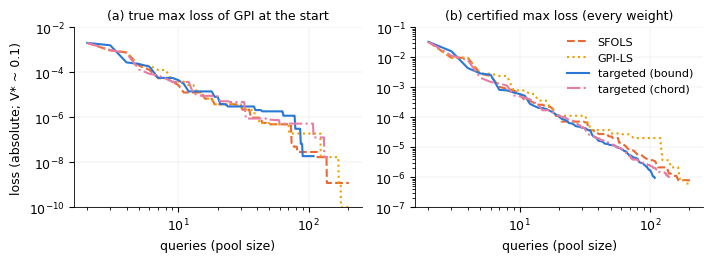

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
for name in ["SFOLS", "GPI-LS", "targeted (bound)", "targeted (chord)"]:
    r = ds[name]; st = STYLE[name]
    x = [c["pool"] for c in r["curve"]]; y = [max(c["max_start"], 1e-10) for c in r["curve"]]
    axes[0].plot(x, y, color=st["color"], ls=st["ls"], label=name)
    cc = r.get("cert_curve") or r.get("cert_log")
    axes[1].plot([c["pool"] for c in cc], [c["cert"] for c in cc], color=st["color"], ls=st["ls"], label=name)
for ax, t in zip(axes, ["(a) true max loss of GPI at the start", "(b) certified max loss (every weight)"]):
    ax.set_yscale("log"); ax.set_xscale("log"); ax.set_xlabel("queries (pool size)"); ax.set_title(t, fontsize=9)
    ax.grid(True, which="major", lw=0.3, alpha=0.4)
axes[0].set_ylabel("loss (absolute; V* ~ 0.1)")
axes[1].legend(frameon=False, loc="upper right")
axes[0].set_ylim(1e-10, 1e-2); axes[1].set_ylim(1e-7, 1e-1)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "gpi_basis_double_slit.pdf")); plt.show()

**Reading.** (a) In this 1-D problem SFOLS' corners already lower GPI's *true* loss as fast as anything else;
selecting by the chord bound (GPI-aware OLS) is marginally faster. (b) What SFOLS lacks is a way to *know*
that GPI is good: its own stopping rule completes the CCS (203 queries). Our certificate proves $\epsilon$-optimal
GPI for every weight much earlier, and targeting the certificate's worst vertex proves it fastest
(109 queries for $10^{-6}$ vs 165 along SFOLS' pool). With Certify-or-Grow every variant learns only 11-13
policies from scratch; all other pool members are certified metapolicies.

## 2. Slippery Office, the three symbol edges (every weight an out-degree-1 FSA task can produce)

Edges $\{C_1,C_2\},\{M_1,M_2\},\{O_1,O_2\}$; loss = max over the 7 relevant states (start + exits) on a 401-point
grid per edge; tasks = 40 random FSAs with out-degree 1, planned with SF-FSA-VI (GPI estimate, as in the paper).

In [4]:
for p in (0.1, 0.3):
    names = [("SFOLS", "sfols_full"), ("SFOLS + CoG", "sfols_cog"), ("GPI-aware OLS + CoG", "gpiols_cog"),
             ("targeted (bound) + CoG", "targeted_bound_cog"), ("targeted (chord) + CoG", "targeted_cog")]
    res = {k: load(f"office_edges_p{p}_{v}.pkl") for k, v in names if os.path.exists(os.path.join(R, f"office_edges_p{p}_{v}.pkl"))}
    print(f"\n=== p = {p} ===")
    print(f"{'':26s}{'queries':>8s}{'full':>6s}" + "".join(f"{'loss<=' + format(e, '.0e'):>13s}" for e in eps)
          + "   task regret with 6 / 8 / 16 policies")
    for k, r in res.items():
        hits = [first(r["curve"], "max_rel", e) for e in eps]
        tr = {c["pool"]: c["task_regret_max"] for c in r["curve"] if "task_regret_max" in c}
        print(f"{k:26s}{r['counters']['queries']:>8d}{r['counters']['full']:>6d}" +
              "".join(f"{str(h):>13s}" for h in hits) + "   " + " / ".join(f"{tr.get(k, float('nan')):.0e}" for k in (6, 8, 16)))
        cc = r.get("cert_curve") or r.get("cert_log")
        if cc:
            print(f"{'   certified at':26s}{'':14s}" + "".join(f"{str(first(cc, 'cert', e)):>13s}" for e in eps))


=== p = 0.1 ===
                           queries  full  loss<=1e-03  loss<=1e-04  loss<=1e-05  loss<=1e-06   task regret with 6 / 8 / 16 policies
SFOLS                          199   199            6           75           75          155   3e-06 / 1e-09 / 1e-09
   certified at                                    50          105          180         None
SFOLS + CoG                    199    16            6           75           75          155   3e-06 / 1e-09 / 1e-09
GPI-aware OLS + CoG            185    16            6           80           80           80   3e-06 / 1e-09 / 1e-09
   certified at                                    48          110         None         None
targeted (bound) + CoG         113    16            6           41           65           65   3e-06 / 3e-06 / 3e-06
   certified at                                    32           65           93          113
targeted (chord) + CoG         185    15            6           65           65           80   3e-06 / 3

## 3. Slippery Office on the full weight simplex ($d=6$, no certificate)

Held-out weights: 600 random on the simplex, 180 on the 2-exit faces, 180 on the 4-exit faces. Tasks: the
paper's 3 tasks + 30 random FSAs with out-degree $\le2$ + 10 with out-degree 3. GPI-greedy queries the weight where
GPI's *true* loss is worst among random candidates: it plans at those candidates, so it is a model-based method.

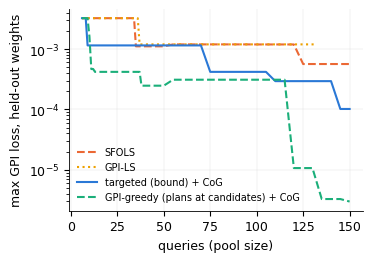


=== p = 0.1 ===  max GPI loss on held-out weights (simplex / 2-exit faces / 4-exit faces) and max task regret
SFOLS                  full=150 | 6: 3e-03/3e-04/4e-04  10: 3e-03/3e-04/4e-04  20: 3e-03/3e-04/4e-04  40: 1e-03/3e-04/4e-04  80: 1e-03/3e-04/4e-04  150: 6e-04/1e-04/8e-05
                       task regret max: 6:2e-05  8:2e-05  11:2e-05  16:2e-05  26:2e-05  150:6e-07
SFOLS + CoG            full= 21 | 6: 3e-03/3e-04/4e-04  10: 3e-03/3e-04/4e-04  20: 3e-03/3e-04/4e-04  40: 3e-03/3e-04/4e-04  80: 1e-03/3e-04/4e-04  150: 1e-03/1e-04/4e-04
                       task regret max: 6:2e-05  8:2e-05  11:2e-05  16:2e-05  26:2e-05  150:8e-06
GPI-aware OLS + CoG    full= 21 | 6: 3e-03/3e-04/4e-04  10: 3e-03/3e-04/4e-04  20: 3e-03/3e-04/4e-04  40: 3e-03/3e-04/4e-04  80: 1e-03/3e-04/4e-04  150: 6e-04/1e-04/8e-05
                       task regret max: 6:2e-05  8:2e-05  11:2e-05  16:2e-05  26:2e-05  150:3e-06
GPI-LS                 full=132 | 6: 3e-03/3e-04/4e-04  10: 3e-03/3e-04/4e-04  20:

In [5]:
for p in (0.1, 0.3):
    names = [("SFOLS", "sfols_full"), ("SFOLS + CoG", "sfols_cog"), ("GPI-aware OLS + CoG", "gpiols_cog"),
             ("GPI-LS", "gpils_full"), ("targeted (bound) + CoG", "targeted_cog"), ("metapolicy probe", "probe"),
             ("GPI-greedy (plans at candidates) + CoG", "oracle_cog")]
    res = {k: load(f"office_full_p{p}_{v}.pkl") for k, v in names if os.path.exists(os.path.join(R, f"office_full_p{p}_{v}.pkl"))}
    if not res:
        continue
    if p == 0.1:
        fig, ax = plt.subplots(figsize=(3.8, 2.7))
        for k, st in (("SFOLS", STYLE["SFOLS"]), ("GPI-LS", STYLE["GPI-LS"]),
                      ("targeted (bound) + CoG", STYLE["targeted (bound)"]), ("GPI-greedy (plans at candidates) + CoG", STYLE["Certify-or-Grow"])):
            if k in res:
                cur = res[k]["curve"]
                ax.plot([c["pool"] for c in cur], [c["max_simplex"] for c in cur], color=st["color"], ls=st["ls"], label=k)
        ax.set_yscale("log"); ax.set_xlabel("queries (pool size)"); ax.set_ylabel("max GPI loss, held-out weights")
        ax.legend(frameon=False, fontsize=7); ax.grid(True, lw=0.3, alpha=0.4)
        fig.tight_layout(); fig.savefig(os.path.join(FIG, "gpi_basis_office_simplex.pdf")); plt.show()
    print(f"\n=== p = {p} ===  max GPI loss on held-out weights (simplex / 2-exit faces / 4-exit faces) and max task regret")
    for k, r in res.items():
        out = []
        for q in (6, 10, 20, 40, 80, 150):
            c = next((c for c in r["curve"] if c["pool"] == q), None)
            if c is not None:
                out.append(f"{q}: {c['max_simplex']:.0e}/{c['max_face1']:.0e}/{c['max_face2']:.0e}")
        tr = [(c["pool"], c["task_regret_max"]) for c in r["curve"] if "task_regret_max" in c]
        print(f"{k:22s} full={r['counters']['full']:3d} | " + "  ".join(out))
        print(f"{'':22s} task regret max: " + "  ".join(f"{q}:{v:.0e}" for q, v in tr))

## 4. Demand-driven certified SF-FSA-VI on a stream of 103 tasks

The paper's 3 tasks + 40 random FSAs with out-degree 1 + 40 with out-degree 2 + 20 with out-degree 3, solved one
after another with a shared pool that starts from the 6 corner policies.

p=0.1: certified regret max 1.1e-16 (exact); paper planning over the 6 corners: max regret 1.3e-05; final pool 24 (13 learned from scratch, 11 certified metapolicies)
p=0.3: certified regret max 1.1e-16 (exact); paper planning over the 6 corners: max regret 6.7e-04; final pool 31 (15 learned from scratch, 16 certified metapolicies)


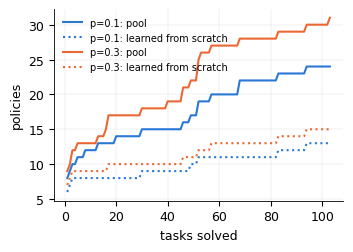

In [6]:
fig, ax = plt.subplots(figsize=(3.6, 2.6))
for p, st in ((0.1, STYLE["targeted (bound)"]), (0.3, STYLE["SFOLS"])):
    r = load(f"office_tasks_p{p}.pkl"); rows = r["rows"]
    opt = np.array([x["opt"] for x in rows]); cert = np.array([x["certified"] for x in rows])
    corn = np.array([x["corners_estimate"] for x in rows])
    full = np.cumsum([x["new_full"] for x in rows]); meta = np.cumsum([x["new_meta"] for x in rows])
    ax.plot(np.arange(1, len(rows) + 1), 6 + full + meta, color=st["color"], ls="-", label=f"p={p}: pool")
    ax.plot(np.arange(1, len(rows) + 1), 6 + full, color=st["color"], ls=":", label=f"p={p}: learned from scratch")
    print(f"p={p}: certified regret max {np.max(opt - cert):.1e} (exact); paper planning over the 6 corners: "
          f"max regret {np.max(opt - corn):.1e}; final pool {len(r['rows']) and 6 + full[-1] + meta[-1]} "
          f"({6 + full[-1]} learned from scratch, {meta[-1]} certified metapolicies)")
ax.set_xlabel("tasks solved"); ax.set_ylabel("policies"); ax.legend(frameon=False, fontsize=7)
ax.grid(True, lw=0.3, alpha=0.4)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "gpi_basis_task_stream.pdf")); plt.show()

## 5. Double slit as a stream of tasks (random weights)

Each new weight is answered demand-driven: nothing is learned if GPI over the pool is certified optimal there.

In [7]:
r = load("ds_stream.pkl"); rows = r["rows"]
g = np.array([x["grew"] for x in rows]); l0 = np.array([x["loss_before"] for x in rows])
for a, b in ((0, 50), (50, 100), (100, 200), (200, 300)):
    print(f"weights {a+1:3d}-{b:3d}: GPI already certified at {100 * (1 - g[a:b].mean()):.0f}% of them; "
          f"true loss before growing: max {l0[a:b].max():.1e}")
print(f"final pool {rows[-1]['pool']} (CCS: 181):", r["counters"])

weights   1- 50: GPI already certified at 58% of them; true loss before growing: max 1.8e-03
weights  51-100: GPI already certified at 82% of them; true loss before growing: max 5.0e-06
weights 101-200: GPI already certified at 91% of them; true loss before growing: max 4.6e-06
weights 201-300: GPI already certified at 93% of them; true loss before growing: max 8.6e-07
final pool 48 (CCS: 181): {'queries': 48, 'full': 13, 'meta_ok': 35, 'meta_fail': 11, 'sweeps_full': 23, 'sweeps_meta': 98}


## 6. Windy two-stage domain: where the corner policies are NOT enough for the tasks

Stage 1 is a double slit (wind $\pm3$) from S to exit A (top) or B (bottom); from A/B calm corridors lead
back to exits C, E (top) and D, F (bottom). Tasks "(A or B) then ..." put their stage-1 weight at different
points of the hedging $\{A,B\}$ edge.

In [8]:
if os.path.exists(os.path.join(R, "windy_stream.pkl")):
    r = load("windy_stream.pkl"); rows = r["rows"]
    opt = np.array([x["opt"] for x in rows]); cert = np.array([x["certified"] for x in rows])
    corn = np.array([x["corners_estimate"] for x in rows])
    ok = opt > 0                                   # some tasks are infeasible (e.g. C is unreachable from B)
    rel = (opt[ok] - corn[ok]) / opt[ok]
    print(f"{len(rows)} two-stage tasks ({ok.sum()} feasible): certified regret max {np.max(opt - cert):.1e}; "
          f"paper planning over the 6 corners: max relative regret {rel.max():.1%}, mean {rel.mean():.2%}, "
          f"tasks with > 1% regret: {np.sum(rel > 0.01)}")
    print("final pool:", rows[-1]["pool"], r["counters"])
for v in ("sfols_full", "targeted_cog", "tchord_cog"):
    f = os.path.join(R, f"windy_edge_{v}.pkl")
    if os.path.exists(f):
        e = load(f"windy_edge_{v}.pkl")
        hits = [first(e["curve"], "max_rel", x) for x in eps]
        cl = e.get("cert_log")
        cert = [first(cl, "cert", x) for x in eps] if cl else None
        print(f"edge {{A,B}} {v:13s}: queries {e['counters']['queries']}, full {e['counters']['full']}; "
              f"true loss <= {eps} at {hits}" + (f"; certified at {cert}" if cert else ""))

60 two-stage tasks (51 feasible): certified regret max 0.0e+00; paper planning over the 6 corners: max relative regret 1.2%, mean 0.26%, tasks with > 1% regret: 11
final pool: 8 {'queries': 8, 'full': 8, 'meta_ok': 0, 'meta_fail': 2, 'sweeps_full': 153, 'sweeps_meta': 3}
edge {A,B} sfols_full   : queries 132, full 132; true loss <= [0.001, 0.0001, 1e-05, 1e-06] at [10, 13, 21, 40]
edge {A,B} targeted_cog : queries 124, full 16; true loss <= [0.001, 0.0001, 1e-05, 1e-06] at [6, 10, 17, 65]; certified at [11, 29, 71, 124]


## Conclusions

1. **Target GPI, not the CCS.** In stochastic domains GPI over a small basis is (near-)optimal long before the
   CCS is complete; the CCS (181 policies on double slit, hundreds on Office edges, >1000 on the Office simplex)
   is the wrong target for SF-FSA-VI.
2. **Certify-or-Grow makes most of any basis free:** with metapolicies only 11-16 policies are ever learned from
   scratch in every experiment, whatever the query rule.
3. **Certificates tell you when to stop.** GPI's cells make "GPI is eps-optimal for every weight" checkable with
   finitely many evaluations along segments; targeting the certificate's worst vertex certifies fastest
   (double slit 1e-6: 109 queries vs 165 along SFOLS' pool vs 203 for the full CCS).
4. **Where to query matters once d > 2.** SFOLS' corners leave GPI's worst-case loss flat for 30-40 queries on the
   6-D Office simplex; GPI-targeted queries reduce it 5x (bound-based) to 190x (GPI-greedy, planning at
   candidates) at 150 queries. In 1-D, SFOLS' corners are already good for the true loss.
5. **For the FSA problem, demand-driven certification is the big win:** every task solved exactly, with a pool of
   24-31 policies for 103 Office tasks and 8 for 60 windy two-stage tasks (where the corners lose up to 1.2%).
6. **Limits:** everything here is model-based; certificates are conservative; full-simplex certification is
   impractical; the model-free (sample-based) version is the next step.